# HVIA Task 01 — Olist Business Discovery
تحليل بيانات Olist 

## 1. Import Liberaries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

## 2. Import olist csv files هنا الملف متقسم

In [ ]:
customers = pd.read_csv("olist_customers_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
cat_translation = pd.read_csv("product_category_name_translation.csv")
orders = pd.read_csv("olist_orders_dataset.csv")

# Convert date columns to datetime format
# pandas----> هتشوف التواريخ والوقت كانهم نصوص فحولتهم لوقت عشان اعرف احسب التاخير بعدين

orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

orders["order_status"].value_counts()  #هنا عرفت حالات الطلبات وعرفت عدد كل حالة

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

## 3. Orders deliver status CHART

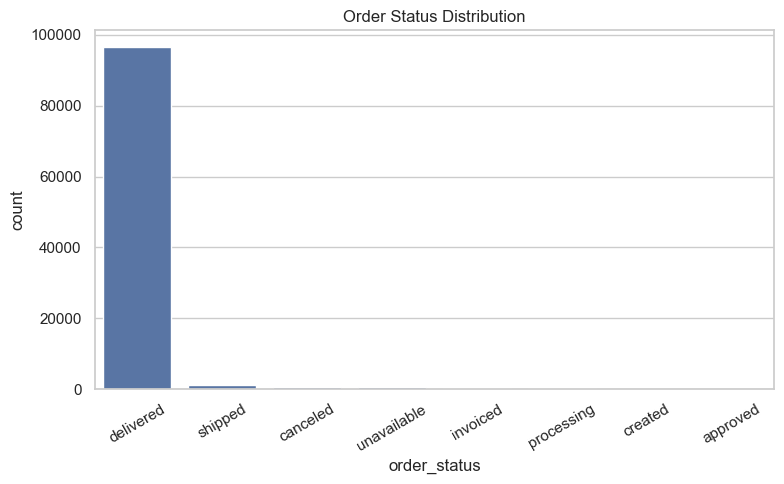

In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=orders, x="order_status", order=orders["order_status"].value_counts().index)
plt.title("Order Status Distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("charts/01_order_status.png")
plt.show()

## 4. Ordering Growth Monthly

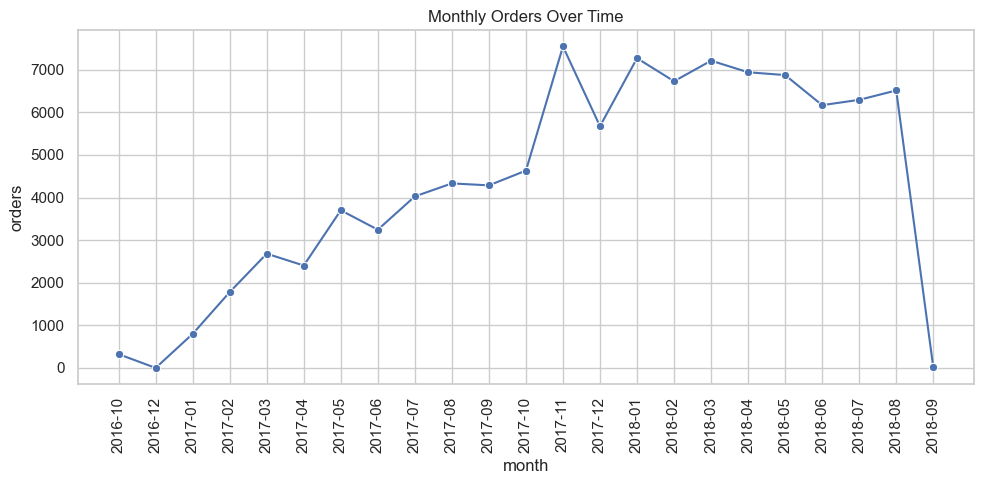

In [ ]:
orders["month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly = orders.groupby("month").size().reset_index(name="orders")
monthly = monthly.iloc[1:-1]  # نشيلت أول وآخر شهر عشان مش كاملين

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="month", y="orders", marker="o")
plt.title("Monthly Orders Over Time")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("charts/02_monthly_orders_trend.png")
plt.show()

In [ ]:
print(monthly)  # جدول فيه عدد الاوردرز لكل شهر
# ده متغير فالميمورى وفت ما بحسب بس عشات يسهل عليا لكن مش بحفظه فالداتا الاصلية

      month  orders
1   2016-10     324
2   2016-12       1
3   2017-01     800
4   2017-02    1780
5   2017-03    2682
6   2017-04    2404
7   2017-05    3700
8   2017-06    3245
9   2017-07    4026
10  2017-08    4331
11  2017-09    4285
12  2017-10    4631
13  2017-11    7544
14  2017-12    5673
15  2018-01    7269
16  2018-02    6728
17  2018-03    7211
18  2018-04    6939
19  2018-05    6873
20  2018-06    6167
21  2018-07    6292
22  2018-08    6512
23  2018-09      16


## 5. علاقة التأخير في التوصيل بتقييم العميل
دى اهم insight


In [11]:

delivered = orders[orders["order_status"] == "delivered"].copy()
delivered["delay_days"] = (delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]).dt.days

late_pct = (delivered["delay_days"] > 0).mean() * 100
print("late deliveries %:", late_pct)

merged = delivered.merge(reviews[["order_id", "review_score"]], on="order_id")
merged["delivery_status"] = merged["delay_days"].apply(lambda x: "Late" if x > 0 else "On Time")

print(merged.groupby("delivery_status")["review_score"].mean())

late deliveries %: 6.77252845208234
delivery_status
Late       2.271025
On Time    4.289999
Name: review_score, dtype: float64


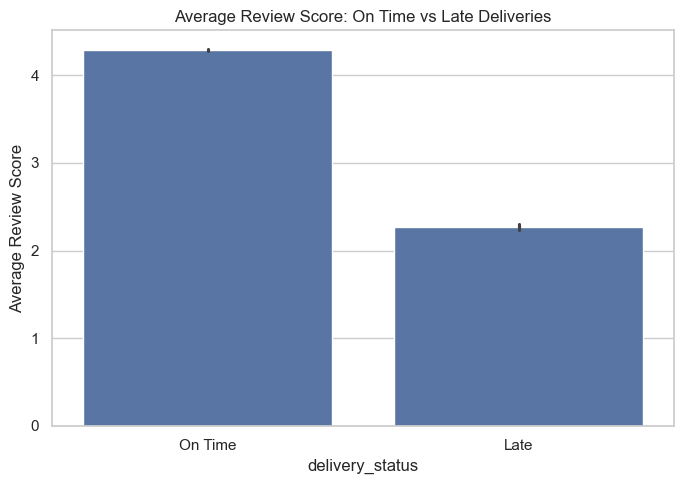

In [12]:
plt.figure(figsize=(7, 5))
sns.barplot(data=merged, x="delivery_status", y="review_score", order=["On Time", "Late"])
plt.title("Average Review Score: On Time vs Late Deliveries")
plt.ylabel("Average Review Score")
plt.tight_layout()
plt.savefig("charts/03_delay_vs_review_score.png")
plt.show()

## 6. اعلى ايرادات فانهى categoeris

In [7]:
item_prod = order_items.merge(products[["product_id", "product_category_name"]], on="product_id")
item_prod = item_prod.merge(cat_translation, on="product_category_name")

top_categories = item_prod.groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).head(10)
print(top_categories)

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64


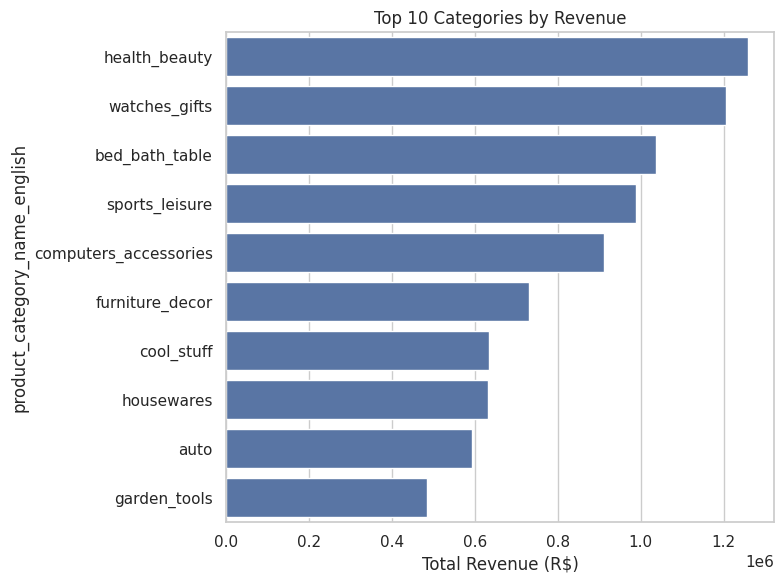

In [8]:
plt.figure(figsize=(8, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)
plt.title("Top 10 Categories by Revenue")
plt.xlabel("Total Revenue (R$)")
plt.tight_layout()
plt.savefig("charts/04_top_categories_revenue.png")
plt.show()

## 7.  أعلى 10% من البائعين بياخدوا كام في المية من إجمالي المبيعات؟

In [9]:
seller_revenue = item_prod.groupby("seller_id")["price"].sum().sort_values(ascending=False)
seller_order_count = order_items.groupby("seller_id")["order_id"].nunique()

top10_n = int(len(seller_revenue) * 0.10)
top10_share = seller_revenue.head(top10_n).sum() / seller_revenue.sum() * 100
print("top 10% sellers revenue share:", top10_share)
print("% sellers with <=10 orders:", (seller_order_count <= 10).mean() * 100)

concentration_df = pd.DataFrame({
    "group": ["Top 10% Sellers", "Other 90%"],
    "revenue_share": [top10_share, 100 - top10_share]
})

top 10% sellers revenue share: 67.41239229328072
% sellers with <=10 orders: 61.19547657512116


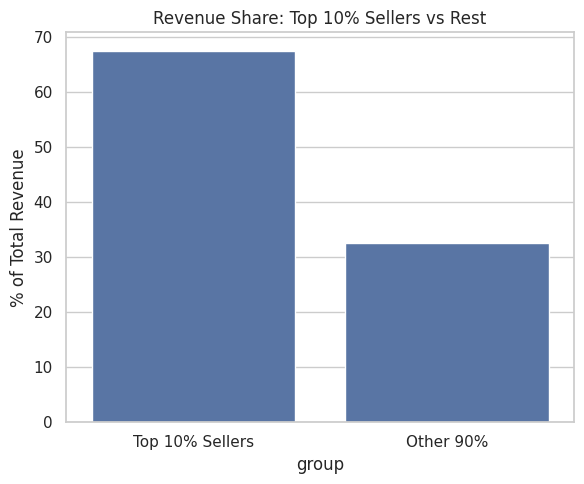

In [10]:
plt.figure(figsize=(6, 5))
sns.barplot(data=concentration_df, x="group", y="revenue_share")
plt.title("Revenue Share: Top 10% Sellers vs Rest")
plt.ylabel("% of Total Revenue")
plt.tight_layout()
plt.savefig("charts/05_seller_concentration.png")
plt.show()

## 8.  عدد العملاء مقابل عدد البائعين في كل ولاية

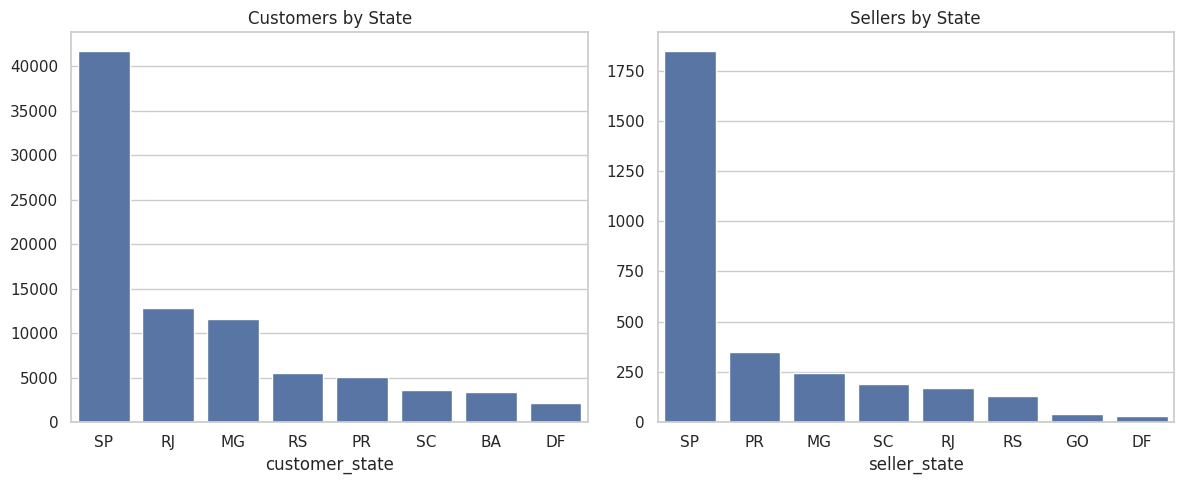

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

top_cust_states = customers["customer_state"].value_counts().head(8)
top_seller_states = sellers["seller_state"].value_counts().head(8)

sns.barplot(x=top_cust_states.index, y=top_cust_states.values, ax=axes[0])
axes[0].set_title("Customers by State")

sns.barplot(x=top_seller_states.index, y=top_seller_states.values, ax=axes[1])
axes[1].set_title("Sellers by State")

plt.tight_layout()
plt.savefig("charts/06_customers_vs_sellers_geography.png")
plt.show()

## 9.  الشحن بين الولايات (Cross State) مقابل نفس الولاية

In [12]:
delivered["delivery_days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days

geo = delivered.merge(customers[["customer_id", "customer_state"]], on="customer_id")
geo = geo.merge(order_items[["order_id", "seller_id", "freight_value", "price"]], on="order_id")
geo = geo.merge(sellers[["seller_id", "seller_state"]], on="seller_id")
geo["same_state"] = geo["customer_state"] == geo["seller_state"]
geo["shipping_type"] = geo["same_state"].map({True: "Same State", False: "Cross State"})

print(geo.groupby("shipping_type")["delivery_days"].mean())
print(geo.groupby("shipping_type")["freight_value"].mean())
print("% cross state orders:", (geo["same_state"] == False).mean() * 100)

shipping_type
Cross State    14.584063
Same State      7.461153
Name: delivery_days, dtype: float64
shipping_type
Cross State    23.632560
Same State     13.449408
Name: freight_value, dtype: float64
% cross state orders: 63.82297158724829


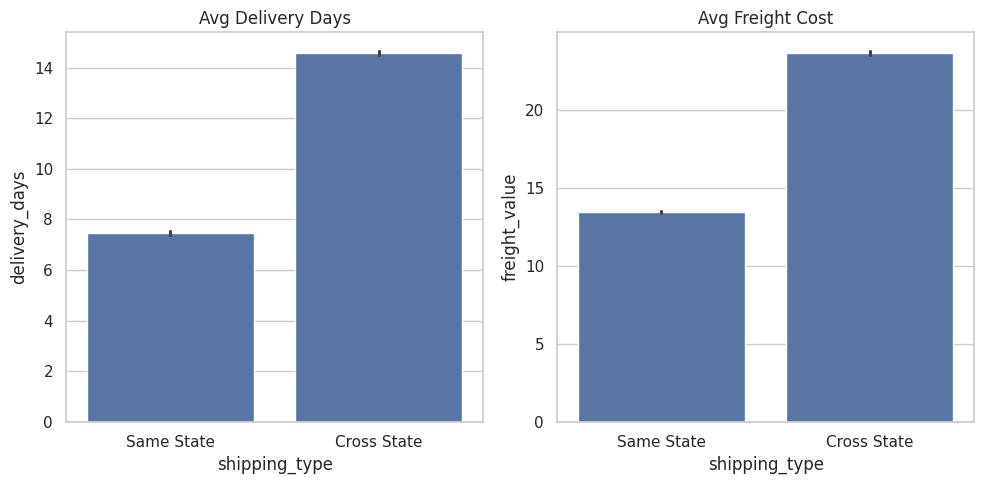

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(data=geo, x="shipping_type", y="delivery_days", ax=axes[0])
axes[0].set_title("Avg Delivery Days")

sns.barplot(data=geo, x="shipping_type", y="freight_value", ax=axes[1])
axes[1].set_title("Avg Freight Cost")

plt.tight_layout()
plt.savefig("charts/07_same_vs_cross_state.png")
plt.show()

## 10.   متوسط أيام التوصيل حسب الولاية (لأكبر 8 ولايات)

In [14]:
top_states_list = customers["customer_state"].value_counts().head(8).index
state_delivery = geo[geo["customer_state"].isin(top_states_list)].groupby("customer_state")["delivery_days"].mean().sort_values(ascending=False)
print(state_delivery)

customer_state
BA    18.774640
RS    14.708299
RJ    14.688821
SC    14.517208
DF    12.501486
MG    11.514091
PR    11.480793
SP     8.259663
Name: delivery_days, dtype: float64


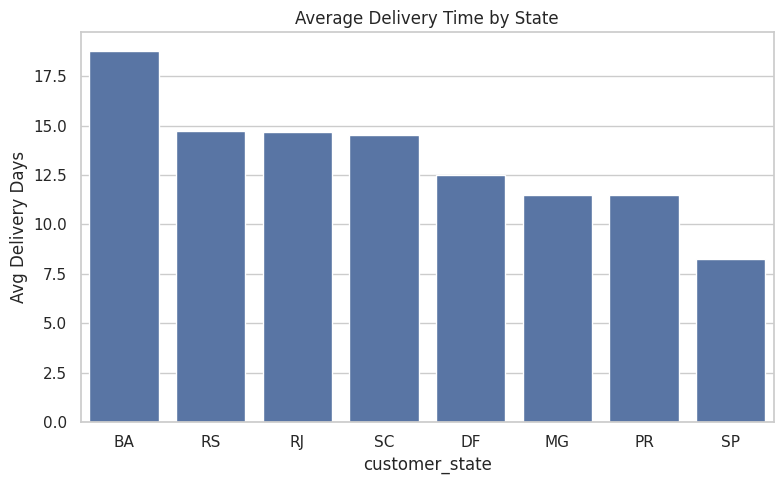

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(x=state_delivery.index, y=state_delivery.values)
plt.title("Average Delivery Time by State")
plt.ylabel("Avg Delivery Days")
plt.tight_layout()
plt.savefig("charts/08_delivery_time_by_state.png")
plt.show()

## 11.   توزيع تقييمات العملاء

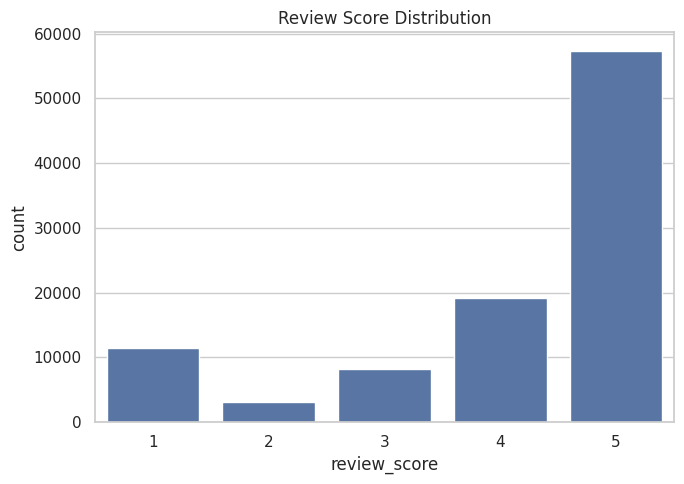

In [17]:
plt.figure(figsize=(7, 5))
sns.countplot(data=reviews, x="review_score")
plt.title("Review Score Distribution")
plt.tight_layout()
plt.savefig("charts/09_review_score_distribution.png")
plt.show()

## 12.  طرق الدفع

In [18]:
payment_counts = payments["payment_type"].value_counts()
print(payment_counts)
print("avg installments:", payments["payment_installments"].mean())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
avg installments: 2.853348863176944


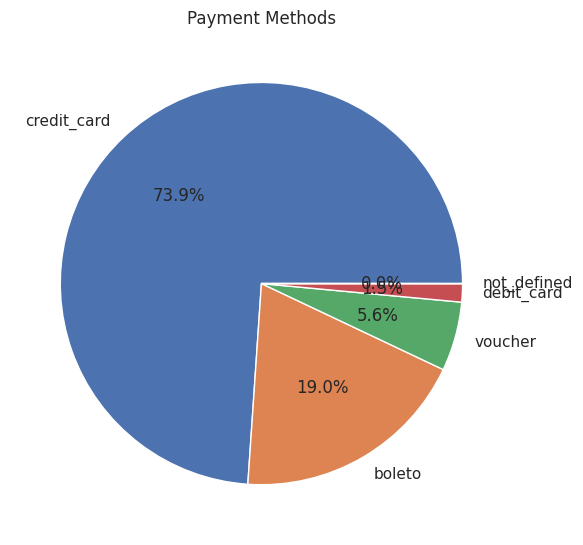

In [19]:
plt.figure(figsize=(6, 6))
plt.pie(payment_counts.values, labels=payment_counts.index, autopct="%1.1f%%")
plt.title("Payment Methods")
plt.tight_layout()
plt.savefig("charts/10_payment_methods.png")
plt.show()

## 13. جودة البيانات (Data Quality)

In [20]:
print(products["product_category_name"].isna().sum(), "products missing category")
print("done - charts saved in charts/ folder")

610 products missing category
done - charts saved in charts/ folder
